In [1]:
from shapely.geometry import Polygon, Point
from functools import cache
import shapely
import numpy as np
import matplotlib.pyplot as plt
import random
from scipy.spatial import Voronoi, voronoi_plot_2d

from artistic_pattern_gen import generate_points, points_on_polygon_boundary, cell_polygons, compare_points, goal_generation, create_rectangle, create_circle, create_triangle

In [2]:
@cache
def goal_generation(polygon, n):
    # generate random points in polygon
    points = generate_points(n, polygon)
    points = np.array([[point.x, point.y] for point in points])
    old_centroids = None

    i = True
    j = 0
    tmp_points = {}
    while i:
        if j % 9 == 0:
            tmp_points[j] = points
        voronoi_polygons = cell_polygons(points, polygon)
        centroids = [shapely.centroid(cell) for cell in voronoi_polygons]
        points = np.array([[point.x, point.y] for point in centroids])

        if old_centroids is not None:
            if compare_points(points, old_centroids):
                i = False

        if i%10 == 0:
            print("Iteration: ", i)
        
        old_centroids = points

        j += 1

    tmp_points[j] = points
    return tmp_points

In [3]:
# Create a circle
circle_center = (-1.5, -1.5)
circle_radius = 1.5
circle_polygon = create_circle(circle_center, circle_radius)

# Create a triangle
triangle_vertices = [(1.5, -2.5), (4.5, -2.5), (3, 1)]
triangle_polygon = create_triangle(triangle_vertices)

# Create a rectangle
rectangle_lower_left = (-1.5, 1.5)
rectangle_upper_right = (1.5, 4.5)
rectangle_polygon = create_rectangle(rectangle_lower_left, rectangle_upper_right)

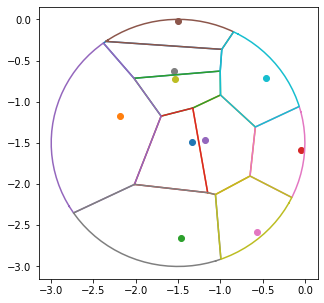

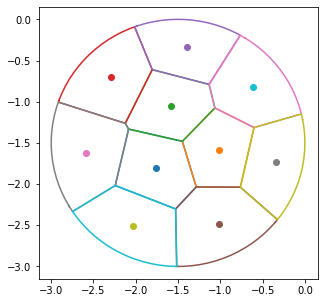

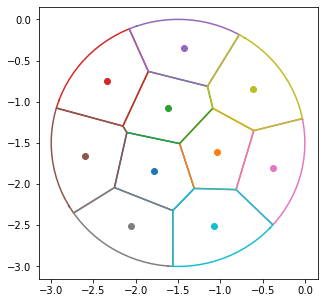

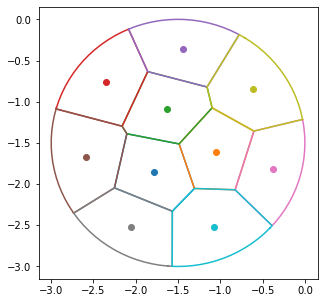

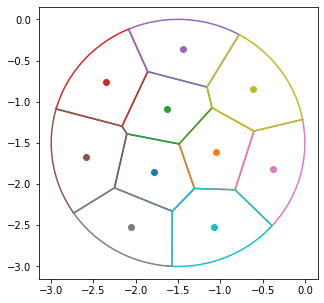

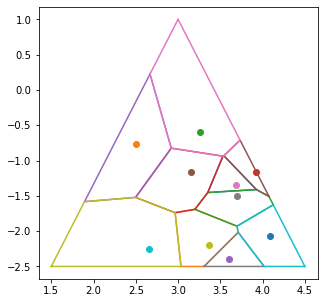

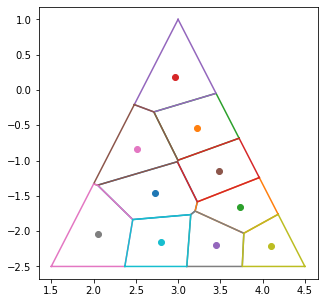

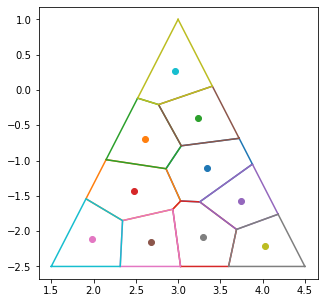

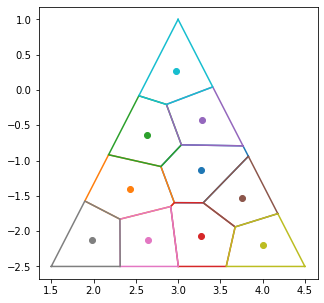

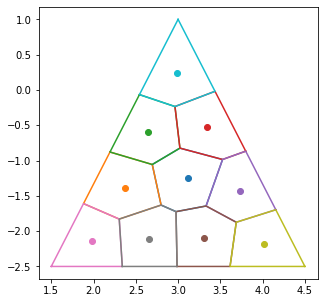

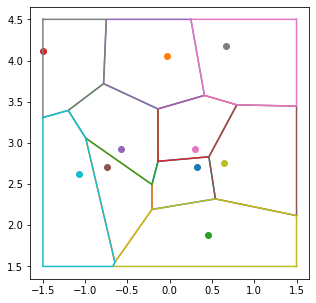

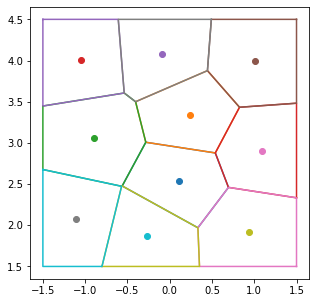

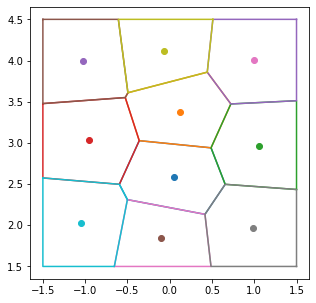

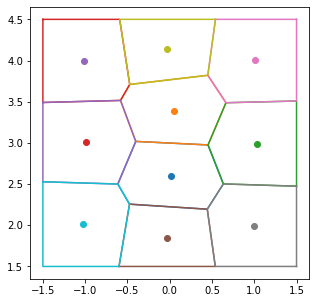

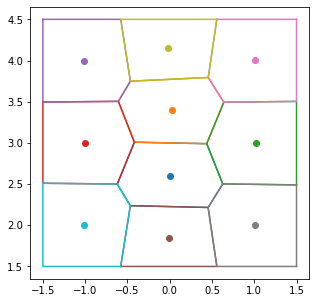

In [7]:
n = 6

names = ["circle", "triangle", "rectangle"]

for j, polygon in enumerate([circle_polygon, triangle_polygon, rectangle_polygon]):
    tmp_points = goal_generation(polygon, 10)

    iterations = list(tmp_points.keys())[:5]
    points = list(tmp_points.values())[:5]
    
    for i, (iteration, points) in enumerate(zip(iterations, points)):
        fig, ax = plt.subplots(1, 1, figsize=(5, 5))
        
        voronoi_polygons = cell_polygons(points, polygon)
    
        for point in points:
            ax.scatter(point[0], point[1])
    
        for cell in voronoi_polygons:
            ax.plot(*cell.exterior.xy)

        plt.savefig("plots/{}_{}.png".format(names[j], iteration))